In [11]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
jam = rng.uniform(1, 9, size=60)
nilai = 35 + 5 * jam + rng.normal(
    loc=0, scale=6, size=60)
df = pd.DataFrame({"jam_belajar": jam,
                   "nilai_ujian": nilai})
print(df)

    jam_belajar  nilai_ujian
0      7.191648    65.763255
1      4.511028    63.364808
2      7.868783    64.246698
3      6.578944    65.885411
4      1.753419    44.743612
5      8.804979    82.542228
6      7.089118    74.712948
7      7.288514    76.202656
8      2.024909    43.032195
9      4.603088    55.241327
10     3.966384    59.979776
11     8.414120    75.922774
12     6.150921    58.100487
13     7.582093    66.110741
14     4.547314    52.219854
15     2.817910    52.072513
16     5.436678    63.037946
17     1.510538    46.695602
18     7.621049    70.541731
19     6.053315    66.217814
20     7.064702    74.077052
21     3.836208    52.324959
22     8.765584    81.568572
23     8.144969    71.753289
24     7.227068    68.957017
25     2.557110    45.495121
26     4.733768    51.493802
27     1.350430    44.673986
28     2.234316    43.355166
29     6.464392    67.396923
30     6.958097    72.674966
31     8.740078    81.379576
32     3.606603    57.025325
33     3.96367

In [12]:
df.head()

,jam_belajar,nilai_ujian
0,7.191648,65.763255
1,4.511028,63.364808
2,7.868783,64.246698
3,6.578944,65.885411
4,1.753419,44.743612


In [15]:
df.shape

(60, 2)

In [17]:
df.isna().sum()

,0
jam_belajar,0
nilai_ujian,0


In [18]:
df.describe()

,jam_belajar,nilai_ujian
count,60.000000,60.000000
mean,5.158475,59.549841
std,2.268995,12.131672
min,1.058898,29.930568
25%,3.184446,50.334266
50%,5.121159,60.134906
75%,7.200503,67.910802
max,8.804979,82.542228


<function matplotlib.pyplot.show(close=None, block=None)>

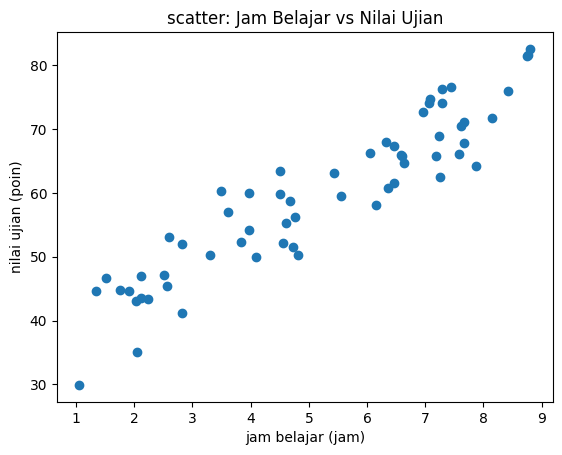

In [22]:
import matplotlib.pyplot as plt
plt.scatter(df['jam_belajar'],
            df['nilai_ujian'])
plt.xlabel('jam belajar (jam)')
plt.ylabel('nilai ujian (poin)')
plt.title('scatter: Jam Belajar vs Nilai Ujian')
plt.show

In [30]:
from sklearn.model_selection import train_test_split
x = df[["jam_belajar"]]
y = df["nilai_ujian"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42)

In [32]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [33]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"model colab: nilai_prediksi = "
      f"{b0:.3f} + ({b1:3f}) x jam_belajar")/

model colab: nilai_prediksi = 34.841 + (4.838508) x jam_belajar


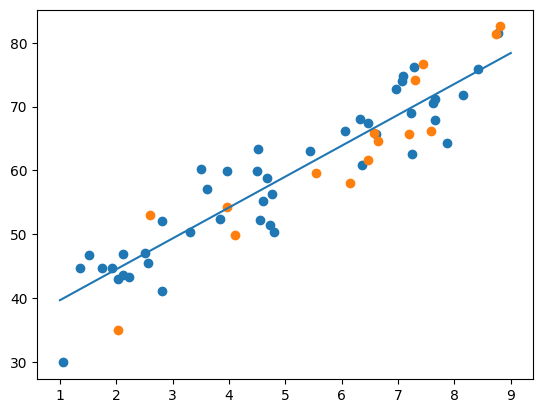

In [36]:
x_grid = pd.DataFrame(
    {"jam_belajar": np.linspace(1, 9, 100)})
y_grid = model.predict(x_grid)
plt.scatter(x_train["jam_belajar"], y_train)
plt.scatter(x_test["jam_belajar"], y_test)
plt.plot(x_grid["jam_belajar"], y_grid)

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_test = model.predict(x_test)
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 4.323764956409487
RMSE: 4.884253621661415
R2  : 0.8388802621811073
